In [142]:
root="../data"

3680 3669


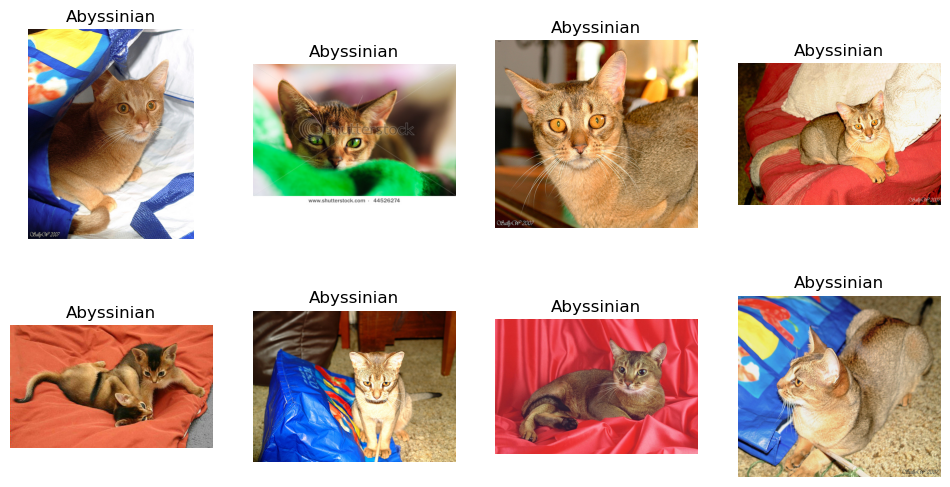

In [143]:
from torchvision.datasets import OxfordIIITPet
import matplotlib.pyplot as plt

train = OxfordIIITPet(root="../data", split="trainval", target_types="category", download=True)
test = OxfordIIITPet(root="../data", split="test", target_types="category", download=True)

print(len(train), len(test))

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, (img, label) in zip(axes.flat, [train[i] for i in range(8)]):
    ax.imshow(img)
    ax.set_title(train.classes[label])
    ax.axis("off")
plt.show()

In [144]:
from collections import Counter
import numpy as np

labels = np.array(train._labels)
counts = Counter(labels)

for cls_id, n in sorted(counts.items(), key=lambda x: x[1]):
    print(f"{train.classes[cls_id]:30s} {n}")

print("\nmin:", min(counts.values()), "max:", max(counts.values()), "classes:", len(counts))

Egyptian Mau                   93
Bombay                         96
English Cocker Spaniel         96
Newfoundland                   96
Siamese                        99
Abyssinian                     100
American Bulldog               100
American Pit Bull Terrier      100
Basset Hound                   100
Beagle                         100
Bengal                         100
Birman                         100
Boxer                          100
British Shorthair              100
Chihuahua                      100
English Setter                 100
German Shorthaired             100
Great Pyrenees                 100
Havanese                       100
Japanese Chin                  100
Keeshond                       100
Leonberger                     100
Maine Coon                     100
Miniature Pinscher             100
Persian                        100
Pomeranian                     100
Pug                            100
Ragdoll                        100
Russian Blue             

width  min/median/max: 114 500 3264
height min/median/max: 108 375 2606
aspect min/median/max: 0.52 1.33 2.56


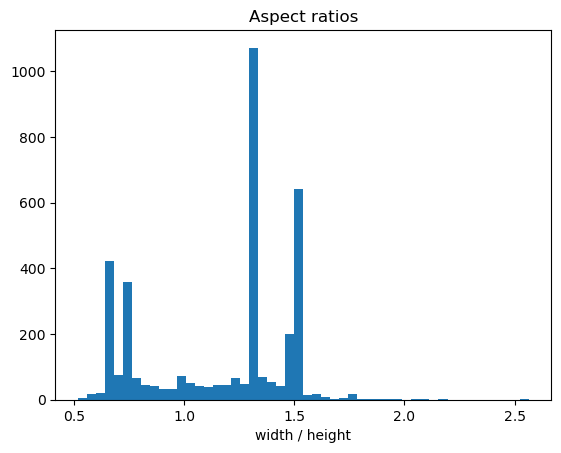

In [145]:
from PIL import Image

sizes = [Image.open(p).size for p in train._images]  # opening a file only reads the header, so this is fast
widths, heights = zip(*sizes)
aspect = np.array(widths) / np.array(heights)

print("width  min/median/max:", min(widths), int(np.median(widths)), max(widths))
print("height min/median/max:", min(heights), int(np.median(heights)), max(heights))
print("aspect min/median/max:", aspect.min().round(2), np.median(aspect).round(2), aspect.max().round(2))

plt.hist(aspect, bins=50); plt.xlabel("width / height"); plt.title("Aspect ratios"); plt.show()

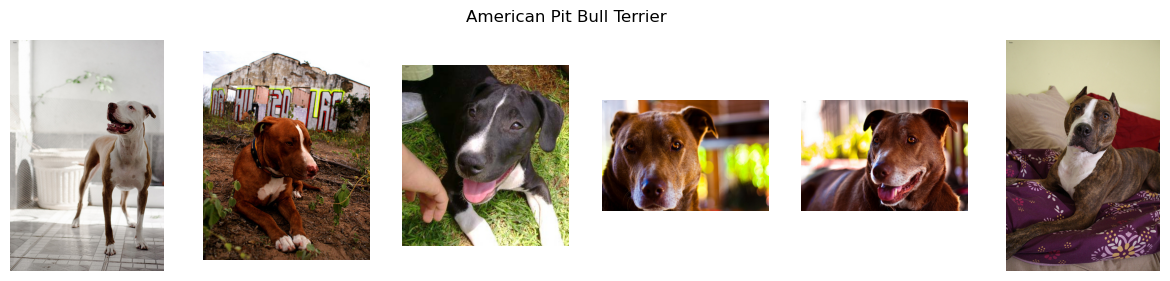

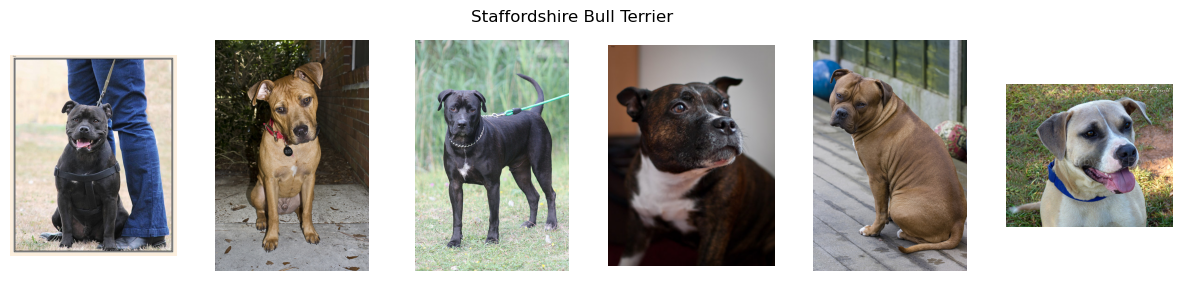

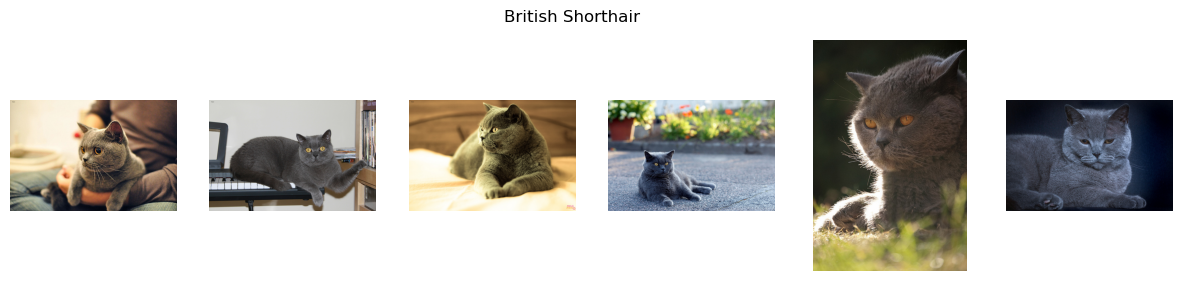

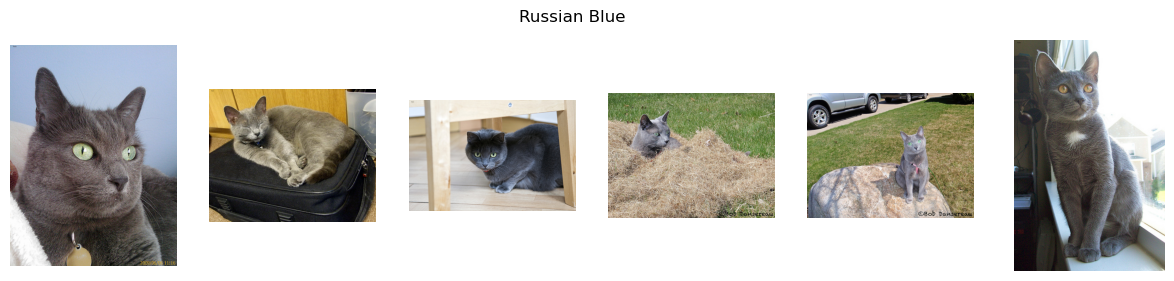

In [146]:
def show_class(name, n=6):
    cls_id = train.classes.index(name)
    idxs = np.where(labels == cls_id)[0][:n]
    fig, axes = plt.subplots(1, n, figsize=(2.5 * n, 3))
    for ax, i in zip(axes, idxs):
        ax.imshow(train[i][0]); ax.axis("off")
    fig.suptitle(name); plt.show()

for name in ["American Pit Bull Terrier", "Staffordshire Bull Terrier", "British Shorthair", "Russian Blue"]:
    show_class(name)

In [147]:
from sklearn.model_selection import train_test_split

all_idx = np.arange(len(train))
train_ix, val_ix = train_test_split(all_idx, test_size = 0.2, stratify = labels, random_state = 42)

print(len(train_ix), len(val_ix)) 

print(np.bincount(labels[train_ix])[:5], np.bincount(labels[val_ix])[:5])

np.save("../data/train_ix.npy", train_ix)
np.save("../data/val_ix.npy", val_ix)

2944 736
[80 80 80 80 80] [20 20 20 20 20]


<class 'PIL.Image.Image'> (333, 500) RGB
0 Abyssinian


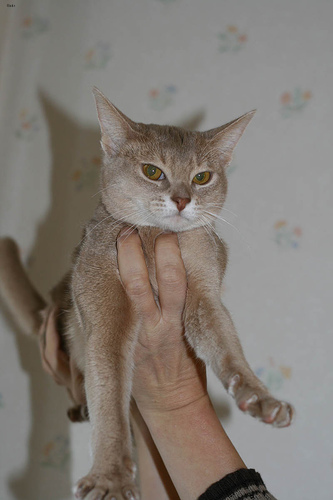

In [148]:
img, label = train[33]
print(type(img), img.size, img.mode)   # a PIL image: (width, height), "RGB"
print(label, train.classes[label])     # an int, and the breed name it stands for
img                                    # a bare PIL image as the last line of a cell shows it inline

In [216]:
#only 80 training images per breed. Flipping, cropping, etc gives additional images of the same image, so there are more for trainig. 
import torch
from torchvision import transforms

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),  # random zoom/crop
    transforms.RandomHorizontalFlip(),                    # a mirrored dog is still the same breed
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

In [217]:
from torch.utils.data import Subset, DataLoader
from torchvision.datasets import OxfordIIITPet

train_idx = np.load("../data/train_ix.npy")
val_idx   = np.load("../data/val_ix.npy")

# same images on disk, two different transforms
base_train = OxfordIIITPet(root="../data", split="trainval", target_types="category", transform=train_tf)
base_eval  = OxfordIIITPet(root="../data", split="trainval", target_types="category", transform=eval_tf)

train_ds = Subset(base_train, train_idx)
val_ds   = Subset(base_eval,  val_idx)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_ds,   batch_size=64, shuffle=False, num_workers=0)

xb, yb = next(iter(train_loader))
print(xb.shape, yb.shape, yb[:10])

torch.Size([32, 3, 224, 224]) torch.Size([32]) tensor([19, 22, 34, 24, 31, 23, 33,  1, 24,  7])


In [151]:
peek_loader = DataLoader(train_ds, batch_size=32, shuffle=False)
xb, yb = next(iter(peek_loader))

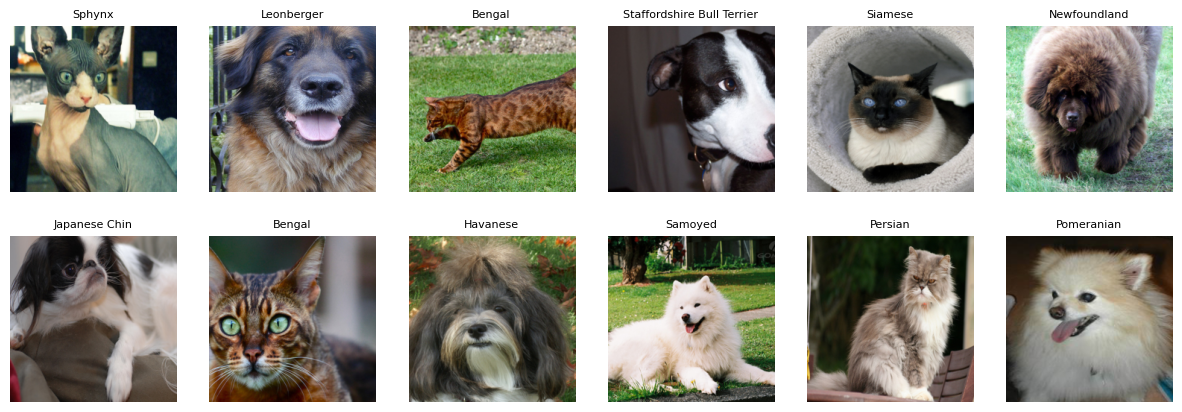

In [152]:
def denorm(x):
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (x * std + mean).clamp(0, 1)

fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for ax, x, y in zip(axes.flat, xb, yb):
    ax.imshow(denorm(x).permute(1, 2, 0))
    ax.set_title(train.classes[y], fontsize=8); ax.axis("off")
plt.show()

In [218]:
import torch.nn as nn
from torchvision import models

device = "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", device)

model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
print(model.fc)   # the original last layer: 512 features -> 1000 ImageNet classes

for p in model.parameters():
    p.requires_grad = False             # freeze everything

model.fc = nn.Linear(model.fc.in_features, 37)   # then replace the head (new layers are trainable by default)
model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f"trainable params: {trainable:,} / {total:,}")

device: mps
Linear(in_features=2048, out_features=1000, bias=True)
trainable params: 75,813 / 23,583,845


In [219]:
import time

def train_one_epoch(model, loader, loss_fn, optimizer):
    model.eval()   # see note below
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)                 # [B, 37] raw scores
        loss = loss_fn(logits, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n

@torch.no_grad()
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n

In [220]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=1e-3)

for epoch in range(5):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch(model, train_loader, loss_fn, optimizer)
    va_loss, va_acc = evaluate(model, val_loader, loss_fn)
    print(f"epoch {epoch+1}  train loss {tr_loss:.3f} acc {tr_acc:.3f}  |  "
          f"val loss {va_loss:.3f} acc {va_acc:.3f}  ({time.time()-t0:.0f}s)")

torch.save(model.state_dict(), "../data/resnet50_linear_probe.pt")

KeyboardInterrupt: 

In [225]:
#start of measuring the performance on each breed and pairs of breeds
model.load_state_dict(torch.load("../data/resnet50_ft_layer4_lr1e-5.pt"))
model.eval()
y_true, y_pred, conf = [], [], []

with torch.no_grad():
    for x, y in val_loader:
        probs = torch.softmax(model(x.to(device)), dim=1)
        p, pred = probs.max(dim=1)          # confidence and predicted class per image
        y_true.append(y.numpy())
        y_pred.append(pred.cpu().numpy())
        conf.append(p.cpu().numpy())

y_true = np.concatenate(y_true)
y_pred = np.concatenate(y_pred)
conf   = np.concatenate(conf)

print("val acc:", (y_true == y_pred).mean())   # should match 0.917

val acc: 0.9538043478260869


In [226]:
per_class = []
for cls_id, name in enumerate(train.classes):
    mask = y_true == cls_id
    per_class.append((name, (y_pred[mask] == cls_id).mean(), mask.sum()))

per_class.sort(key=lambda r: r[1])
for name, acc, n in per_class[:10]:
    print(f"{name:30s} {acc:.2f}  (n={n})")

American Pit Bull Terrier      0.85  (n=20)
Boxer                          0.85  (n=20)
British Shorthair              0.85  (n=20)
Egyptian Mau                   0.89  (n=19)
Abyssinian                     0.90  (n=20)
Birman                         0.90  (n=20)
Chihuahua                      0.90  (n=20)
Miniature Pinscher             0.90  (n=20)
Ragdoll                        0.90  (n=20)
Russian Blue                   0.90  (n=20)


In [227]:
from collections import Counter

CATS = {"Abyssinian", "Bengal", "Birman", "Bombay", "British Shorthair", "Egyptian Mau",
        "Maine Coon", "Persian", "Ragdoll", "Russian Blue", "Siamese", "Sphynx"}

wrong = np.where(y_true != y_pred)[0]
pairs = Counter((train.classes[y_true[i]], train.classes[y_pred[i]]) for i in wrong)

print(f"{len(wrong)} mistakes\n")
for (t, p), n in pairs.most_common(10):
    print(f"{n}x  {t:28s} -> {p}")

cross = sum((train.classes[y_true[i]] in CATS) != (train.classes[y_pred[i]] in CATS) for i in wrong)
print("\ncat/dog mix-ups:", cross)

34 mistakes

3x  Boxer                        -> American Bulldog
3x  British Shorthair            -> Russian Blue
2x  American Pit Bull Terrier    -> Miniature Pinscher
2x  Russian Blue                 -> British Shorthair
2x  Birman                       -> Ragdoll
2x  Ragdoll                      -> Birman
2x  Egyptian Mau                 -> Bengal
1x  Beagle                       -> Basset Hound
1x  Saint Bernard                -> Beagle
1x  Miniature Pinscher           -> Chihuahua

cat/dog mix-ups: 0


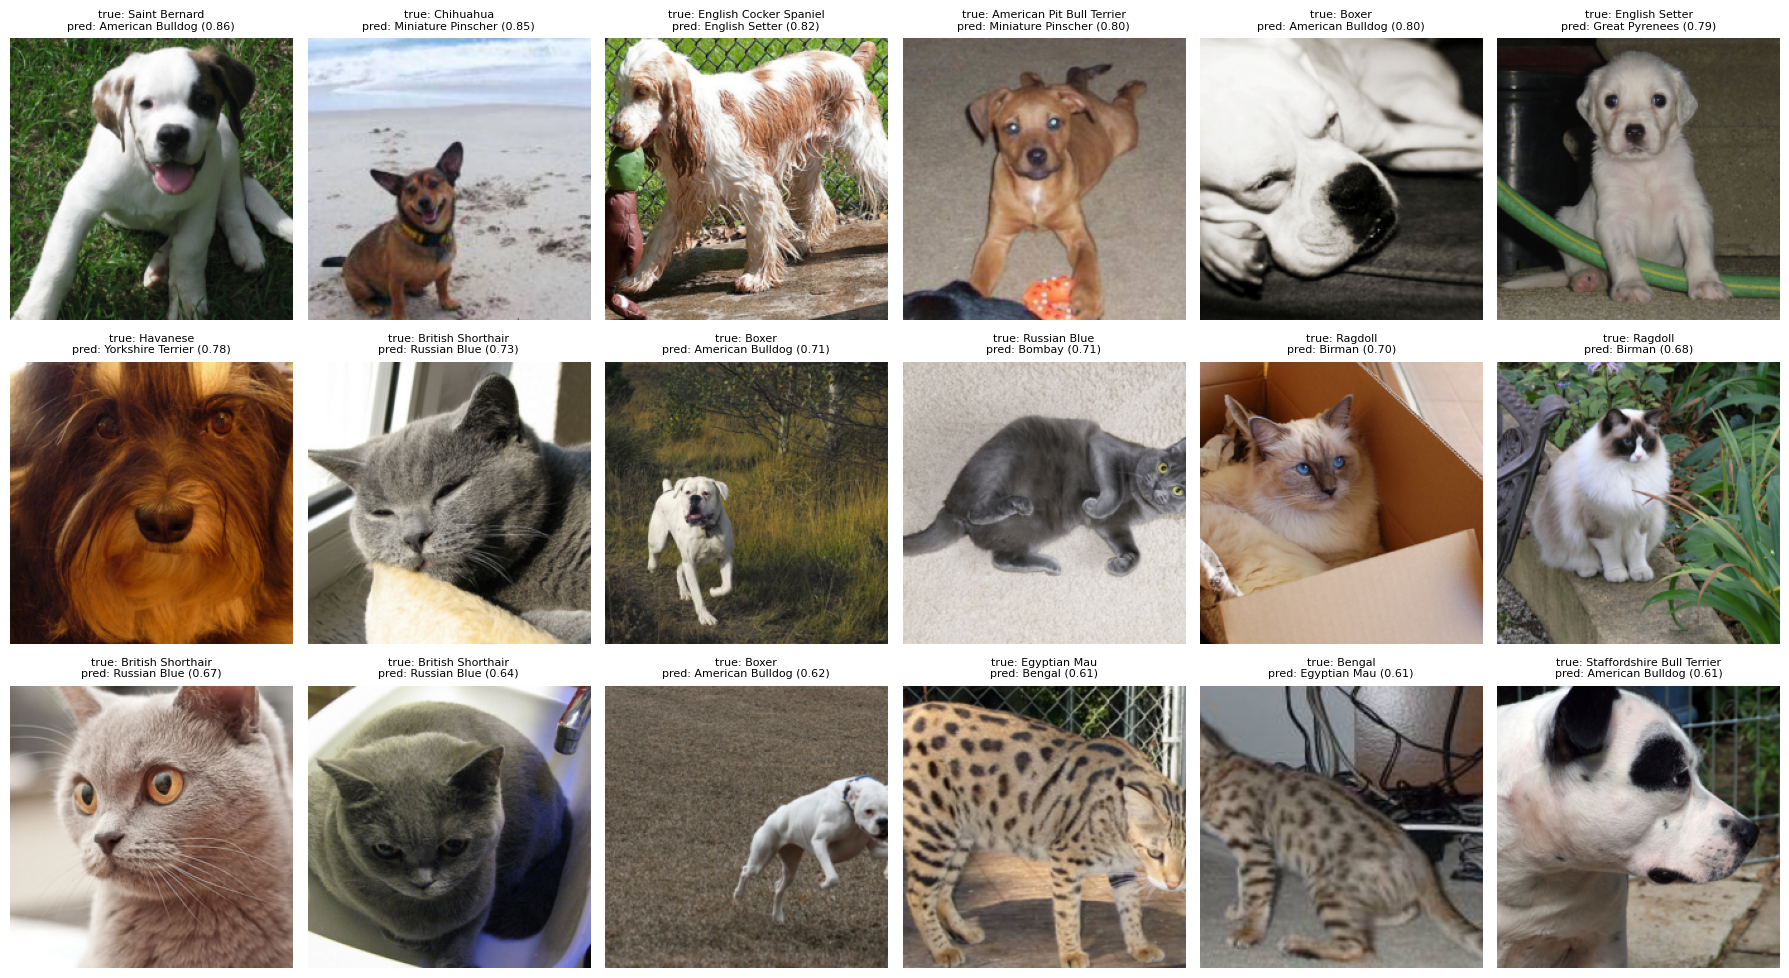

In [159]:
order = wrong[np.argsort(-conf[wrong])]

fig, axes = plt.subplots(3, 6, figsize=(18, 10))
for ax, i in zip(axes.flat, order):
    x, _ = val_ds[i]
    ax.imshow(denorm(x).permute(1, 2, 0))
    ax.set_title(f"true: {train.classes[y_true[i]]}\npred: {train.classes[y_pred[i]]} ({conf[i]:.2f})",
                 fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

In [222]:
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False
model.fc = nn.Linear(model.fc.in_features, 37)

model.load_state_dict(torch.load("../data/resnet50_linear_probe.pt", map_location="cpu"))

for p in model.layer4.parameters():
    p.requires_grad = True              # unfreeze the last block

model = model.to(device)

trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
total     = sum(p.numel() for p in model.parameters())
print(f"trainable params: {trainable:,} / {total:,}")

trainable params: 15,040,549 / 23,583,845


In [223]:
def set_train_mode(model):
    model.train()
    for module in [model.conv1, model.bn1, model.layer1, model.layer2, model.layer3]:
        module.eval()                   # frozen parts keep their ImageNet BatchNorm stats

def train_one_epoch_ft(model, loader, loss_fn, optimizer):
    set_train_mode(model)
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        loss = loss_fn(logits, y)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(y)
        correct += (logits.argmax(1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n

In [224]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam([
    {"params": model.layer4.parameters(), "lr": 1e-5},   # small: adjust pretrained features
    {"params": model.fc.parameters(),     "lr": 1e-3},   # same as the linear probe
])

best_acc = 0.0
for epoch in range(10):
    t0 = time.time()
    tr_loss, tr_acc = train_one_epoch_ft(model, train_loader, loss_fn, optimizer)
    va_loss, va_acc = evaluate(model, val_loader, loss_fn)

    saved = ""
    if va_acc > best_acc:
        best_acc = va_acc
        torch.save(model.state_dict(), "../data/resnet50_ft_layer4_lr1e-5.pt")
        saved = "  * saved"

    print(f"epoch {epoch+1}  train loss {tr_loss:.3f} acc {tr_acc:.3f}  |  "
          f"val loss {va_loss:.3f} acc {va_acc:.3f}  ({time.time()-t0:.0f}s){saved}")

print("best val acc:", best_acc)

epoch 1  train loss 0.146 acc 0.963  |  val loss 0.196 acc 0.942  (45s)  * saved
epoch 2  train loss 0.085 acc 0.981  |  val loss 0.182 acc 0.943  (44s)  * saved
epoch 3  train loss 0.063 acc 0.985  |  val loss 0.189 acc 0.940  (51s)
epoch 4  train loss 0.050 acc 0.991  |  val loss 0.184 acc 0.943  (60s)
epoch 5  train loss 0.036 acc 0.993  |  val loss 0.183 acc 0.936  (58s)
epoch 6  train loss 0.028 acc 0.995  |  val loss 0.170 acc 0.944  (59s)  * saved
epoch 7  train loss 0.019 acc 0.998  |  val loss 0.175 acc 0.950  (57s)  * saved
epoch 8  train loss 0.022 acc 0.995  |  val loss 0.175 acc 0.944  (52s)
epoch 9  train loss 0.018 acc 0.996  |  val loss 0.170 acc 0.947  (53s)
epoch 10  train loss 0.019 acc 0.997  |  val loss 0.174 acc 0.954  (54s)  * saved
best val acc: 0.9538043478260869


In [ ]:
# evaluate run 7's checkpoint at several input resolutions (no retraining) to see if it's worth trying the different resolutions
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 37)
model.load_state_dict(torch.load("../data/resnet50_ft_layer4_lr1e-5.pt", map_location="cpu"))
model = model.to(device)

sizes = [(256, 224), (288, 256), (320, 288), (384, 352)]   # (resize, center crop)

for resize, crop in sizes:
    res_tf = transforms.Compose([
        transforms.Resize(resize),
        transforms.CenterCrop(crop),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])
    res_base   = OxfordIIITPet(root="../data", split="trainval", target_types="category", transform=res_tf)
    res_val_ds = Subset(res_base, val_idx)
    res_loader = DataLoader(res_val_ds, batch_size=64, shuffle=False, num_workers=0)

    t0 = time.time()
    va_loss, va_acc = evaluate(model, res_loader, loss_fn)
    print(f"resize {resize}, crop {crop}:  val loss {va_loss:.3f}  acc {va_acc:.3f}  "
          f"({round((1 - va_acc) * len(res_val_ds))} mistakes, {time.time()-t0:.0f}s)")

resize 256, crop 224:  val loss 0.174  acc 0.954  (34 mistakes, 7s)
resize 288, crop 256:  val loss 0.161  acc 0.957  (32 mistakes, 9s)
resize 320, crop 288:  val loss 0.177  acc 0.936  (47 mistakes, 11s)
resize 384, crop 352:  val loss 0.255  acc 0.933  (49 mistakes, 14s)


In [229]:
# FINAL: score run 7 once on the official test split
model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 37)
model.load_state_dict(torch.load("../data/resnet50_ft_layer4_lr1e-5.pt", map_location="cpu"))
model = model.to(device)

test_ds     = OxfordIIITPet(root="../data", split="test", target_types="category", transform=eval_tf)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=0)

te_loss, te_acc = evaluate(model, test_loader, loss_fn)
print(f"test images: {len(test_ds)}")
print(f"test loss {te_loss:.3f}  acc {te_acc:.4f}  ({round((1 - te_acc) * len(test_ds))} mistakes)")

test images: 3669
test loss 0.267  acc 0.9253  (274 mistakes)
